In [1]:
# Loading Basic Libraries 
import os
import gc   # No Version
from pathlib import Path

import random
import six
import sys
import warnings

import dataclasses
from dataclasses import dataclass, field
from typing import Dict, Any, Tuple, Union, List, Optional, Mapping
from tqdm import tqdm
from tqdm.notebook import tqdm

import yaml
import pickle

In [2]:
# Loading Data Processing Libraries 
import numpy as np
import pandas as pd

from logging import getLogger

In [3]:
# Loading Visualization Libraries 
from IPython.core.display import display, HTML
import matplotlib.pyplot as plt
import matplotlib.patches as ptc
# import seaborn as sns

# from plotly import tools, subplots
# import plotly.offline as py

# import plotly.graph_objs as go
# import plotly.express as px
# import plotly.figure_factory as ff
# import plotly.io as pio

/tmp/ipykernel_709/3356634764.py:2: DeprecationWarning: Importing display from IPython.core.display is deprecated since IPython 7.14, please import from IPython display
  from IPython.core.display import display, HTML


In [4]:
# Loading Imaging Libraries 
import pydicom as pdc
from pydicom.pixel_data_handlers.util import apply_voi_lut
import cv2
# import albumentations as A

In [5]:
# Loading Statistics Libraries 
import scipy as sp

# Loading Models Libraries 
from sklearn import preprocessing
from sklearn.model_selection import StratifiedKFold, KFold
# import lightgbm as lgb
import xgboost as xgb
# import catboost as cb

import torch
import torch.nn.functional as F
from torch import nn
from torch.nn import Linear
from torch import nn, optim
from torch.utils.data.dataloader import DataLoader
from torch.utils.data.dataset import Dataset

# from ignite.engine import Events, Engine

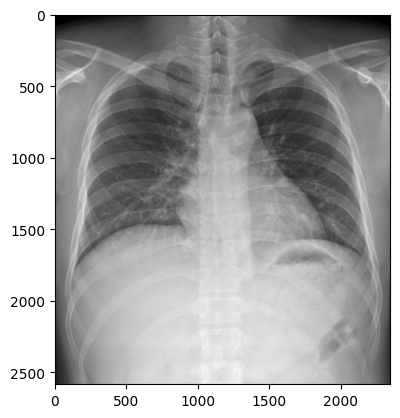

In [6]:
from pydicom import dcmread

ds = dcmread("../vu2/test/002a34c58c5b758217ed1f584ccbcfe9.dicom")

arr = ds.pixel_array

plt.imshow(arr, cmap="gray")
plt.show()

In [18]:
import pandas as pd
import random
from torchvision import transforms

class VinBigDataDataset(Dataset):
    def __init__(self, csv_file, img_dir, transform=None, num_samples=300):
        self.annotations = pd.read_csv(csv_file)
        self.img_dir = img_dir
        self.transform = transform
        
        # Randomly sample the specified number of samples
#         self.annotations = self.annotations.sample(n=num_samples, random_state=42).reset_index(drop=True)

    def __len__(self):
        return len(self.annotations)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.annotations.iloc[idx, 0] + ".dicom")
        dicom_image = pydicom.dcmread(img_path)
        
        # Convert to uint8 by scaling the pixel values
        img = dicom_image.pixel_array
        img = img.astype(np.uint8)  # Convert uint16 to uint8 by truncation

        # Optionally normalize the pixel values to the [0, 255] range
        img = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX)

        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)  # Convert to RGB
        img = cv2.resize(img, (224, 224))  # Resize for VGG16

        if self.transform:
            img = self.transform(img)

        label = int(self.annotations.iloc[idx, 2])  # class_id
        return img, label

In [19]:
# Hyperparameters and configuration
num_classes = 15  # 14 abnormalities + "No finding"
batch_size = 16
learning_rate = 0.001
num_epochs = 2

# Transformations for DICOM images
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Dataset paths
train_csv = "../vu2/train.csv"
train_img_dir = "../vu2/test/"
test_img_dir = "../vu2/test/"

In [24]:
from torch.utils.data import random_split
full_dataset = VinBigDataDataset(
    csv_file='../vu2/train.csv',
    img_dir='../vu2/train',
    transform=transform,
    num_samples=300
)

# # Set the random seed for reproducibility
# random_seed = 42

# # Define split sizes for train, validation, and test
# train_size = int(0.6 * len(full_dataset))  # 60% for training
# val_size = int(0.2 * len(full_dataset))    # 20% for validation
# test_size = len(full_dataset) - train_size - val_size  # Remaining 20% for testing

# # Split the dataset into train, validation, and test sets
# train_dataset, val_dataset, test_dataset = random_split(
#     full_dataset, 
#     [train_size, val_size, test_size], 
#     generator=torch.Generator().manual_seed(random_seed)  # Use the random seed
# )

# # Save each split to a file using pickle
# with open("../vu2/CXR/train_dataset.pkl", "wb") as f:
#     pickle.dump(train_dataset, f)

# with open("../vu2/CXR/val_dataset.pkl", "wb") as f:
#     pickle.dump(val_dataset, f)

# with open("../vu2/CXR/test_dataset.pkl", "wb") as f:
#     pickle.dump(test_dataset, f)

# print("Datasets saved to files: train_dataset.pkl, val_dataset.pkl, and test_dataset.pkl.")

with open("../vu2/CXR/train_dataset.pkl", "rb") as f:
    train_dataset = pickle.load(f)

with open("../vu2/CXR/val_dataset.pkl", "rb") as f:
    val_dataset = pickle.load(f)

with open("../vu2/CXR/test_dataset.pkl", "rb") as f:
    test_dataset = pickle.load(f)

# DataLoaders for training and validation
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)


# Display dataset sizes
print(f"Train dataset size: {len(train_dataset)}")
print(f"Validation dataset size: {len(val_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

Train dataset size: 40748
Validation dataset size: 13582
Test dataset size: 13584


In [27]:
import torch
import torchvision.models as models

# Model, loss, and optimizer
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Define the number of output classes

# Load the pretrained ResNet-50 model
model = models.resnet50(pretrained=True)

# Modify the final fully connected layer to match the number of classes
model.fc = torch.nn.Linear(model.fc.in_features, num_classes)

# Move the model to the appropriate device (GPU or CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("ResNet-50 model loaded with a custom number of output classes.")

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /home/runai-home/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100%|██████████| 97.8M/97.8M [00:01<00:00, 80.7MB/s]


ResNet-50 model loaded with a custom number of output classes.


In [36]:
import pydicom
from tqdm import tqdm

# Training function
def train(model, train_loader, criterion, optimizer, num_epochs):
    model.train()
    for epoch in range(num_epochs):
        print('epoch:',epoch)
        running_loss = 0.0
        train_loader_tqdm = tqdm(train_loader, desc="Training", leave=True)

        for images, labels in train_loader_tqdm:
            images, labels = images.to(device), labels.to(device)

            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Backward and optimize
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {running_loss / len(train_loader):.4f}')

In [ ]:
train(model, train_loader, criterion, optimizer, num_epochs)

epoch: 0


Training:   4%|▎         | 47/1274 [12:21<5:23:27, 15.82s/it]

In [35]:
print(device)

cuda
